In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
data = {
    'X': [-2, -1, 0, 1, 2],
    'Y': [9, 2, 1, 6, 17]
}

df = pd.DataFrame(data)

print(df)

   X   Y
0 -2   9
1 -1   2
2  0   1
3  1   6
4  2  17


In [3]:
X = df[['X']]
y = df['Y']

In [4]:
poly = PolynomialFeatures(degree=2)

X_poly = poly.fit_transform(X)

print("Polynomial Features:")
print(X_poly)

Polynomial Features:
[[ 1. -2.  4.]
 [ 1. -1.  1.]
 [ 1.  0.  0.]
 [ 1.  1.  1.]
 [ 1.  2.  4.]]


In [5]:
model = LinearRegression()

model.fit(X_poly, y)

print("Model Trained Successfully")

Model Trained Successfully


In [6]:
print("Intercept:", model.intercept_)

print("Coefficients:", model.coef_)

print("\nPolynomial Regression Equation:")

print(
    "Y =",
    model.intercept_,
    "+",
    model.coef_[1], "* X",
    "+",
    model.coef_[2], "* X^2"
)

Intercept: 1.0
Coefficients: [0. 2. 3.]

Polynomial Regression Equation:
Y = 1.0 + 2.0000000000000004 * X + 3.0 * X^2


In [7]:
y_pred = model.predict(X_poly)

print("Actual Values:", y.values)

print("Predicted Values:", y_pred)

Actual Values: [ 9  2  1  6 17]
Predicted Values: [ 9.  2.  1.  6. 17.]


In [8]:
mse = mean_squared_error(y, y_pred)

r2 = r2_score(y, y_pred)

print("Mean Squared Error:", mse)

print("R2 Score:", r2)

Mean Squared Error: 3.944304526105059e-32
R2 Score: 1.0


C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:464: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


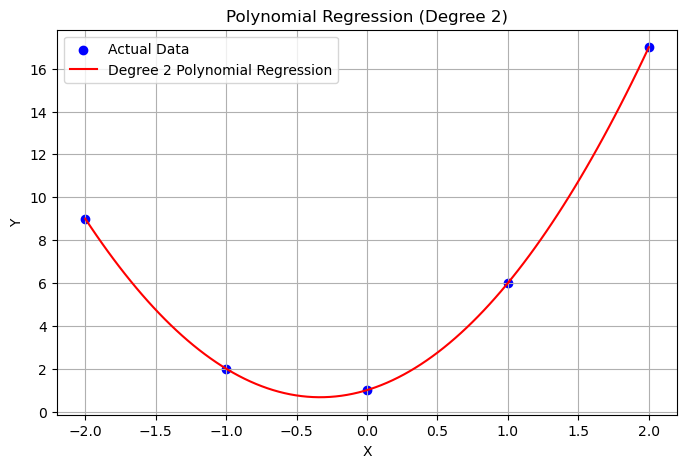

In [9]:
X_range = np.linspace(-2, 2, 100).reshape(-1, 1)

X_range_poly = poly.transform(X_range)

y_range_pred = model.predict(X_range_poly)

plt.figure(figsize=(8, 5))

plt.scatter(X, y, color='blue', label='Actual Data')

plt.plot(
    X_range,
    y_range_pred,
    color='red',
    label='Degree 2 Polynomial Regression'
)

plt.xlabel('X')
plt.ylabel('Y')

plt.title('Polynomial Regression (Degree 2)')

plt.legend()
plt.grid(True)

plt.show()